# 02 — Features: sensor selection and causal rolling features

**Goal:** turn raw FD001 sensors into model inputs that every AML model can share.

- **Feature selection:** keep the 14 informative sensors (rule and evidence in `01_eda.ipynb`), decided on the 80 training engines only.
- **Time series features:** trailing rolling **mean**, **standard deviation** and **slope** per sensor, using only the current and past cycles of the same engine.
- **Scaling:** `StandardScaler` fitted on the training engines only.
- **Protocol:** `docs/EVALUATION_PROTOCOL.md` (no RUL cap, 80/20 engine split, seed 42).

Run this notebook from the `notebooks/` folder.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from rul_prediction.data import load_cmapss_file
from rul_prediction.features import (
    DEFAULT_WINDOW,
    add_rolling_features,
    model_feature_columns,
    select_informative_sensors,
)
from rul_prediction.splits import sample_cutoff_rows, split_by_engine, split_engine_ids
from rul_prediction.targets import add_train_rul

RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Split first, then select sensors on training engines

In [2]:
train = add_train_rul(load_cmapss_file(RAW_DIR / "train_FD001.txt"))
train_ids, val_ids = split_engine_ids(train["engine_id"])
train_df, val_df = split_by_engine(train, val_ids)
test = load_cmapss_file(RAW_DIR / "test_FD001.txt")

sensors = select_informative_sensors(train_df)
FEATURES = model_feature_columns(sensors, DEFAULT_WINDOW)

print(f"informative sensors ({len(sensors)}):", sensors)
print(f"window: {DEFAULT_WINDOW} cycles | model features: {len(FEATURES)} "
      f"(cycle + {len(sensors)} raw + {len(sensors)} x mean/std/slope)")
print("engine_id used as a feature:", "engine_id" in FEATURES)

informative sensors (14): ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
window: 10 cycles | model features: 57 (cycle + 14 raw + 14 x mean/std/slope)
engine_id used as a feature: False


## 2. Build features per split

Each table is processed on its own; every rolling window stays inside one engine, so it does not matter which other engines are in the table. Test features come from `test_FD001.txt` alone.

In [3]:
train_feat = add_rolling_features(train_df, sensors)
val_feat = add_rolling_features(val_df, sensors)
test_feat = add_rolling_features(test, sensors)

for name, table in [("train", train_feat), ("validation", val_feat), ("test", test_feat)]:
    print(f"{name:10s} rows {len(table):6d} | engines {table['engine_id'].nunique():3d} | "
          f"missing feature values {int(table[FEATURES].isna().sum().sum())}")

train      rows  16390 | engines  80 | missing feature values 0
validation rows   4241 | engines  20 | missing feature values 0
test       rows  13096 | engines 100 | missing feature values 0


## 3. Hand-inspected example: engine 1, `sensor_11`, first 12 cycles

Check by eye: at cycle 1 the mean equals the reading and std/slope are 0; up to cycle 10 the window grows; from cycle 11 it slides (cycles 2–11, then 3–12).

In [4]:
example_cols = ["engine_id", "cycle", "sensor_11"] + [f"sensor_11_{s}_w{DEFAULT_WINDOW}" for s in ("mean", "std", "slope")]
example = train_feat[train_feat["engine_id"] == 1][example_cols].head(12)

# Recompute cycle 12's mean by hand from the raw readings of cycles 3-12.
raw_engine_1 = train_df[train_df["engine_id"] == 1].set_index("cycle")["sensor_11"]
by_hand = raw_engine_1.loc[3:12].mean()
print(f"cycle 12 mean by hand: {by_hand:.4f} | from features: {example.iloc[-1, 3]:.4f}")
example.round(4)

cycle 12 mean by hand: 47.2090 | from features: 47.2090


,engine_id,cycle,sensor_11,sensor_11_mean_w10,sensor_11_std_w10,sensor_11_slope_w10
0,1,1,47.47,47.4700,0.0000,0.0000
1,1,2,47.49,47.4800,0.0141,0.0200
2,1,3,47.27,47.4100,0.1217,-0.1000
3,1,4,47.13,47.3400,0.1717,-0.1240
4,1,5,47.28,47.3280,0.1511,-0.0740
5,1,6,47.16,47.3000,0.1515,-0.0663
6,1,7,47.36,47.3086,0.1402,-0.0350
7,1,8,47.24,47.3000,0.1320,-0.0290
8,1,9,47.29,47.2989,0.1235,-0.0210
9,1,10,47.03,47.2720,0.1442,-0.0299


## 4. Causality check on the real validation cut-off points

The protocol scores validation engines at 100 cut-off cycles. That is only fair if each feature row at cycle *c* would be identical had the engine stopped at *c*. Here every validation engine is truncated at each of its cut-offs, features are rebuilt, and the row at *c* is compared with the full-history version.

In [5]:
val_points = sample_cutoff_rows(val_feat)

max_difference = 0.0
for engine_id, cut_cycle in val_points[["engine_id", "cycle"]].itertuples(index=False):
    history = val_df[(val_df["engine_id"] == engine_id) & (val_df["cycle"] <= cut_cycle)]
    truncated_row = add_rolling_features(history, sensors).iloc[-1][FEATURES]
    full_row = val_feat[(val_feat["engine_id"] == engine_id) & (val_feat["cycle"] == cut_cycle)].iloc[0][FEATURES]
    max_difference = max(max_difference, float(np.abs(truncated_row.to_numpy(float) - full_row.to_numpy(float)).max()))

assert max_difference < 1e-9, max_difference
print(f"checked {len(val_points)} cut-off points; largest difference: {max_difference:.2e}")

checked 100 cut-off points; largest difference: 0.00e+00


## 5. What the rolling features look like (training engine)

Raw `sensor_11` is noisy and the rolling mean follows its trend. The 10-cycle rolling slope is itself noisy; for this engine it is positive more often as failure approaches, and it swings strongly in the first cycles when the window holds few points.

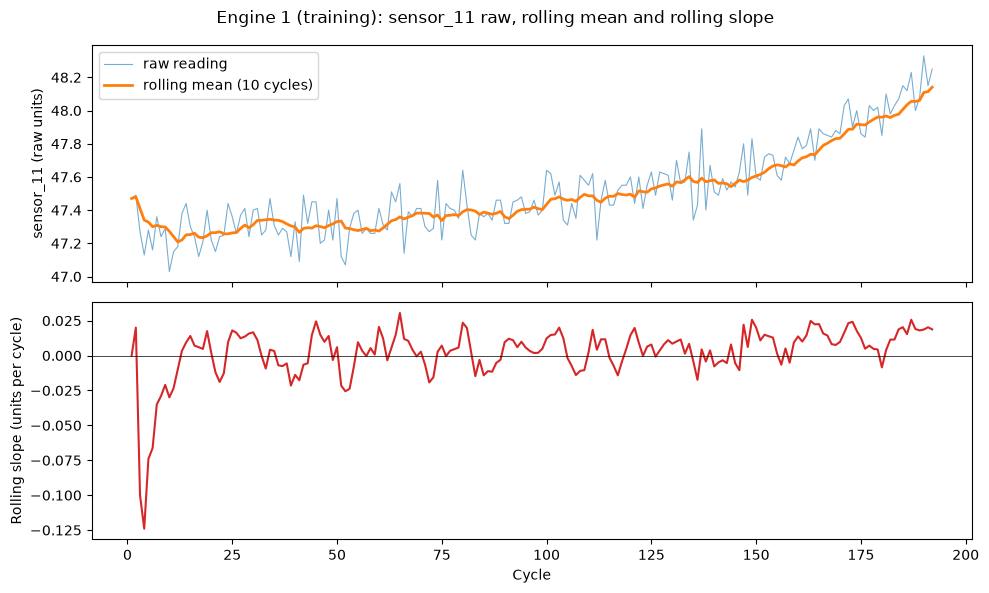

In [6]:
engine_id = train_ids[0]
engine = train_feat[train_feat["engine_id"] == engine_id]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
top.plot(engine["cycle"], engine["sensor_11"], linewidth=0.8, alpha=0.6, label="raw reading")
top.plot(engine["cycle"], engine[f"sensor_11_mean_w{DEFAULT_WINDOW}"], linewidth=2, label=f"rolling mean ({DEFAULT_WINDOW} cycles)")
top.set_ylabel("sensor_11 (raw units)")
top.legend()
bottom.plot(engine["cycle"], engine[f"sensor_11_slope_w{DEFAULT_WINDOW}"], color="tab:red")
bottom.axhline(0, color="black", linewidth=0.5)
bottom.set_xlabel("Cycle")
bottom.set_ylabel("Rolling slope (units per cycle)")
fig.suptitle(f"Engine {engine_id} (training): sensor_11 raw, rolling mean and rolling slope")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "features_sensor_11_rolling.png", dpi=150)
plt.show()

In [7]:
# How often is the slope positive, by how far the engine is from failure? (one engine only)
slope_column = f"sensor_11_slope_w{DEFAULT_WINDOW}"
rul_band = pd.cut(engine["rul"], bins=[-1, 25, 50, 100, engine["rul"].max()], labels=["0-25", "26-50", "51-100", "101+"])
(engine[slope_column] > 0).groupby(rul_band, observed=True).mean().round(2).rename("share of cycles with positive slope")

rul
0-25      0.96
26-50     0.76
51-100    0.68
101+      0.53
Name: share of cycles with positive slope, dtype: float64

## 6. Does smoothing help? Correlation with RUL on training engines

Supporting evidence only (training engines). Whether the features improve a model is decided by re-running the baselines on validation.

In [8]:
corr = pd.DataFrame({
    "raw": [train_feat[s].corr(train_feat["rul"]) for s in sensors],
    "rolling_mean": [train_feat[f"{s}_mean_w{DEFAULT_WINDOW}"].corr(train_feat["rul"]) for s in sensors],
    "rolling_slope": [train_feat[f"{s}_slope_w{DEFAULT_WINDOW}"].corr(train_feat["rul"]) for s in sensors],
}, index=sensors)
gain = corr["rolling_mean"].abs() - corr["raw"].abs()
print("sensors where |corr| rises by more than 0.01:", int((gain > 0.01).sum()), "of", len(sensors))
print("sensors with a change of 0.01 or less:", gain[gain.abs() <= 0.01].index.tolist())
corr.round(3)

sensors where |corr| rises by more than 0.01: 12 of 14
sensors with a change of 0.01 or less: ['sensor_9', 'sensor_14']


,raw,rolling_mean,rolling_slope
sensor_2,-0.615,-0.730,-0.112
sensor_3,-0.596,-0.738,-0.092
sensor_4,-0.687,-0.741,-0.147
sensor_7,0.667,0.722,0.131
sensor_8,-0.570,-0.599,-0.158
sensor_9,-0.419,-0.423,-0.227
sensor_11,-0.704,-0.736,-0.176
sensor_12,0.678,0.715,0.176
sensor_13,-0.569,-0.600,-0.151
sensor_14,-0.334,-0.334,-0.199


## 7. Scaling: fitted on training engines only

`StandardScaler` learns each feature's mean and standard deviation. Fitting it on validation or test rows would leak their distribution into training, so it is fitted on `train_feat` and only *applied* to the others. Model notebooks should keep the scaler inside an sklearn pipeline (as `03_linear_baseline.ipynb` does), which enforces the same rule.

In [9]:
scaler = StandardScaler().fit(train_feat[FEATURES])

assert np.allclose(scaler.mean_, train_feat[FEATURES].mean().to_numpy())
train_scaled = scaler.transform(train_feat[FEATURES])
val_scaled = scaler.transform(val_feat[FEATURES])

print(f"train: mean of scaled features {train_scaled.mean():.3f}, std {train_scaled.std():.3f}")
print(f"validation (scaled with training statistics): mean {val_scaled.mean():.3f}, std {val_scaled.std():.3f}")

train: mean of scaled features -0.000, std 1.000
validation (scaled with training statistics): mean -0.001, std 1.014


## Findings

_All values come from the cell outputs above._

- **Features:** 57 model inputs = `cycle` + 14 informative raw sensors + 14 × rolling mean / std / slope (window 10 cycles). `engine_id` is kept for splitting and ordering but is **not** a model input.
- **Complete:** 0 missing feature values in train (16,390 rows, 80 engines), validation (4,241 rows, 20 engines) and test (13,096 rows, 100 engines).
- **Hand check:** for engine 1, `sensor_11` at cycle 12, the mean of cycles 3–12 computed by hand (47.2090) equals the feature value. At cycle 1, mean = reading and std = slope = 0.
- **No future information:** at all 100 validation cut-off points, rebuilding features on the history truncated at the cut-off gives exactly the same row (largest difference 0). So scoring at cut-off rows is equivalent to scoring truncated engines, as the protocol requires.
- **Rolling mean helps (training engines):** for 12 of 14 sensors the rolling mean correlates more strongly with RUL than the raw reading by more than 0.01 (e.g. `sensor_2` −0.615 → −0.730, `sensor_17` −0.613 → −0.736); `sensor_9` and `sensor_14` are essentially unchanged. This matches the noisy readings seen in `01_eda.ipynb`.
- **Rolling slope is weak at this window:** |corr with RUL| only 0.08–0.23. Over 10 cycles the trend is small compared with sensor noise. For engine 1, the `sensor_11` slope is positive in 53% of cycles with RUL > 100, rising to 96% of the last 25 cycles (one engine only). A longer slope window is a candidate experiment, compared on **validation** only.
- **Scaling:** `StandardScaler` fitted on training engines only (its means equal the training means). Training features have mean 0.000 / std 1.000; validation, scaled with training statistics, has mean −0.001 / std 1.014, which is close but not exact, as expected for unseen engines.

**Limitations / next steps:**

- **Short windows in early rows:** cycles 1–9 of each training/validation engine have fewer than 10 points, so their std/slope are 0 or noisy. Every test row and validation cut-off has at least 31 cycles of history, so models are scored only on full windows. Training on early rows is a modelling choice; training on cycles >= 10 only can be compared on validation.
- **`cycle` as a feature:** allowed by the protocol and known at test time, but a model may use it as an age proxy. An ablation without `cycle`, scored on validation, would show how much models rely on it.
- Correlation is single-feature evidence only. Whether these 57 features beat the 24 raw ones must be shown by re-running the linear baseline (Abhayanth) and tree models (Srijan) on the shared validation points. The window length (10) has not been tuned yet. PCA is still an optional later experiment.